# ResNet + Deformable Convolution v2 (DCNv2)

**Paper:** Zhu, X., Hu, H., Lin, S., & Dai, J. (2019). Deformable ConvNets v2: More Deformable, Better Results. *CVPR 2019*. https://arxiv.org/abs/1811.11168

**Original DCNv1:** Dai, J., et al. (2017). Deformable Convolutional Networks. *ICCV 2017*. https://arxiv.org/abs/1703.06211

**Implementation:** `hale_core/nn/vision/cnn/resnet_dcn.py`

> Standard convolutions sample a fixed rectangular grid. Deformable convolutions learn per-position offsets that adapt the sampling pattern to the geometry of each image, enabling better modelling of non-rigid transformations.

> 📄 **Paper:** Zhu, Hu, Lin & Dai (2019). Deformable ConvNets v2: More Deformable, Better Results. CVPR 2019.
> 🔗 **Link:** <https://arxiv.org/abs/1811.11168>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/resnet_dcn.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, H, W)"]:::io --> STEM["ResNet stem /4"]:::stage
  STEM --> L1["layer1: plain Bottlenecks /4"]:::stage --> L2["layer2: DCN Bottlenecks /8"]:::stage
  L2 --> L3["layer3: DCN Bottlenecks /16"]:::stage --> L4["layer4: DCN Bottlenecks /32"]:::stage --> GAP["global avg pool"]:::block --> OUT
  subgraph DCN["Modulated deformable conv 3×3 (DCNv2)"]
    direction LR
    F["features"] --> OFF["offset/mask conv 3×3<br/>→ 2·9 offsets + 9 masks (sigmoid)"]:::block
    F --> SMP["bilinear sample at p + p_k + Δp_k"]:::block
    OFF --> SMP --> W["Σ_k w_k · m_k · x(p + p_k + Δp_k)"]:::block
  end
  L2 -.-> DCN
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
ResNet-50 DCN:  Same as ResNet-50 except stages 2 & 3 use DCNBottleneck

Input [B,3,H,W]
  → Stem (7×7 conv, MaxPool)     → [B,  64, H/4, W/4]
  → Stage 0: Bottleneck ×3       → [B, 256, H/4, W/4]   (standard conv)
  → Stage 1: Bottleneck ×4       → [B, 512, H/8, W/8]   (standard conv)
  → Stage 2: DCNBottleneck ×6    → [B,1024, H/16,W/16]  ← deformable 3×3
  → Stage 3: DCNBottleneck ×3    → [B,2048, H/32,W/32]  ← deformable 3×3
  → GlobalAvgPool → [B, 2048]

Inside DCNBottleneck:
  x → 1×1 BN+ReLU (squeeze)
    → ┌─────────────────────────────────────────────┐
      │  DeformConv2d (replaces standard 3×3 conv)  │
      │  ┌──────────────────────────────────────┐   │
      │  │ offset_conv(x) → [B, 2k², H, W]     │   │ → Δy, Δx per grid point
      │  │ mask_conv(x)   → [B, k², H, W]      │   │ → sigmoid weights [0,1]
      │  │ grid_sample(x, base+offset)           │   │ → bilinear sampling
      │  │ einsum(sampled * mask, weight)        │   │ → output features
      │  └──────────────────────────────────────┘   │
      └─────────────────────────────────────────────┘
    → BN+ReLU
    → 1×1 BN (expand)
    → (+skip) → ReLU

Key difference DCNv1 vs DCNv2:
  DCNv1: learns offsets only (Δy, Δx) — 2k² extra channels
  DCNv2: learns offsets + modulation masks — 2k² + k² extra channels
         The mask gates each sample: low mask → ignore noisy context
```

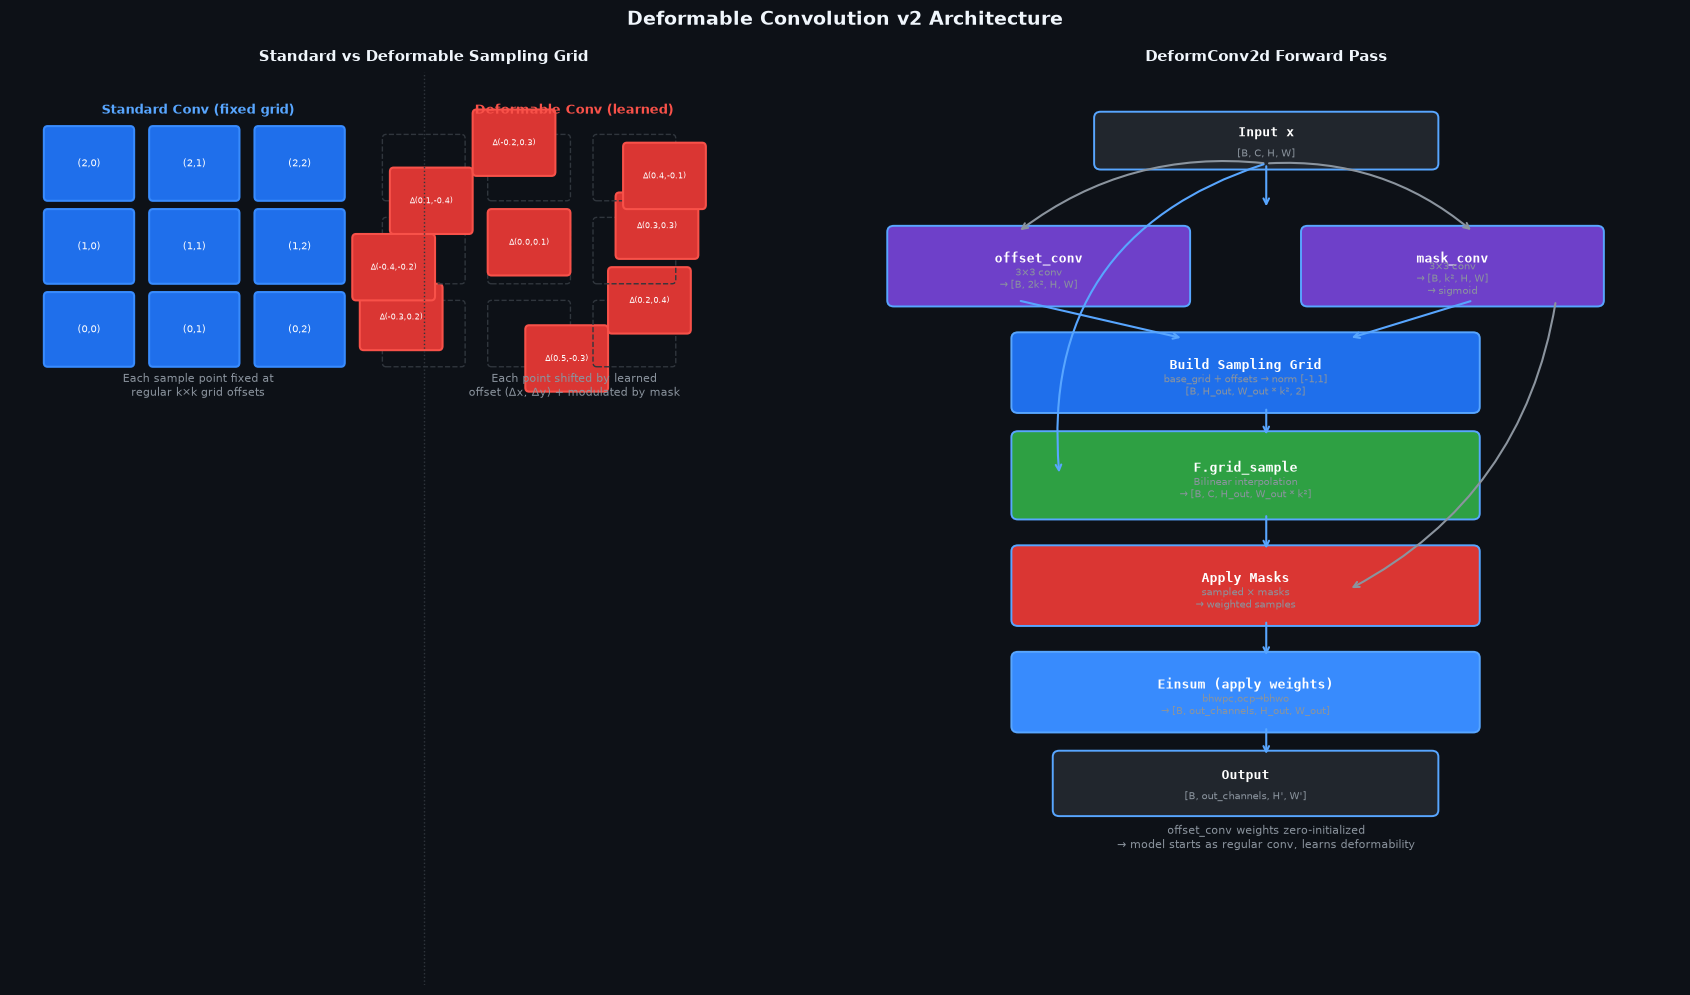

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(17, 10))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#0d1117')
    ax.axis('off')

def box(ax, x, y, w, h, label, sublabel='', color='#1f6feb', fontsize=9):
    rect = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.08',
                           facecolor=color, edgecolor='#58a6ff', linewidth=1.4)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2 + (0.10 if sublabel else 0), label,
            ha='center', va='center', color='white', fontsize=fontsize,
            fontweight='bold', fontfamily='monospace')
    if sublabel:
        ax.text(x + w/2, y + h/2 - 0.17, sublabel,
                ha='center', va='center', color='#8b949e', fontsize=7)

def arr(ax, x1, y1, x2, y2, c='#58a6ff'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=c, lw=1.5))

# ── LEFT: Standard 3×3 conv grid vs Deformable ──────────────────────────────
ax = axes[0]
ax.set_xlim(0, 11)
ax.set_ylim(0, 11)
ax.set_title('Standard vs Deformable Sampling Grid', color='#f0f6fc',
             fontsize=11, fontweight='bold', pad=8)

# Standard grid (fixed 3x3)
ax.text(2.5, 10.5, 'Standard Conv (fixed grid)', ha='center',
        color='#58a6ff', fontsize=9, fontweight='bold')
for i in range(3):
    for j in range(3):
        rect = FancyBboxPatch((0.5 + j*1.4, 7.5 + i*1.0), 1.1, 0.8,
                               boxstyle='round,pad=0.05',
                               facecolor='#1f6feb', edgecolor='#388bfd', lw=1.5)
        ax.add_patch(rect)
        ax.text(1.05 + j*1.4, 7.9 + i*1.0, f'({i},{j})',
                ha='center', va='center', color='white', fontsize=7)

ax.text(2.5, 7.1, 'Each sample point fixed at\nregular k×k grid offsets',
        ha='center', color='#8b949e', fontsize=8)

# Deformable grid
ax.text(7.5, 10.5, 'Deformable Conv (learned)', ha='center',
        color='#f85149', fontsize=9, fontweight='bold')

# irregular sampling points
offsets = [(-0.3, 0.2), (0.5, -0.3), (0.2, 0.4),
           (-0.4, -0.2), (0.0, 0.1), (0.3, 0.3),
           (0.1, -0.4), (-0.2, 0.3), (0.4, -0.1)]
for i in range(3):
    for j in range(3):
        idx = i*3 + j
        ox, oy = offsets[idx]
        base_x = 5.0 + j*1.4 + ox
        base_y = 7.5 + i*1.0 + oy
        # Original position (ghost)
        rect0 = FancyBboxPatch((5.0 + j*1.4, 7.5 + i*1.0), 1.0, 0.7,
                                boxstyle='round,pad=0.05',
                                facecolor='none', edgecolor='#30363d', lw=1, linestyle='--')
        ax.add_patch(rect0)
        # Shifted position
        rect1 = FancyBboxPatch((base_x, base_y), 1.0, 0.7,
                                boxstyle='round,pad=0.05',
                                facecolor='#da3633', edgecolor='#f85149', lw=1.5)
        ax.add_patch(rect1)
        ax.text(base_x + 0.5, base_y + 0.35, f'Δ({ox:.1f},{oy:.1f})',
                ha='center', va='center', color='white', fontsize=6)

ax.text(7.5, 7.1, 'Each point shifted by learned\noffset (Δx, Δy) + modulated by mask',
        ha='center', color='#8b949e', fontsize=8)

# Divider
ax.axvline(5.5, color='#30363d', lw=1, linestyle=':')

# ── RIGHT: DeformConv2d pipeline ──────────────────────────────────────────────
ax = axes[1]
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.set_title('DeformConv2d Forward Pass', color='#f0f6fc',
             fontsize=11, fontweight='bold', pad=8)

box(ax, 3, 10.8, 4, 0.6, 'Input x', '[B, C, H, W]', color='#21262d')
arr(ax, 5, 10.8, 5, 10.2)

# Two parallel branches
box(ax, 0.5, 9.0, 3.5, 0.9, 'offset_conv', '3×3 conv\n→ [B, 2k², H, W]', color='#6e40c9')
box(ax, 5.5, 9.0, 3.5, 0.9, 'mask_conv', '3×3 conv\n→ [B, k², H, W]\n→ sigmoid', color='#6e40c9')

ax.annotate('', xy=(2.0, 9.9), xytext=(5, 10.8),
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1.5,
                            connectionstyle='arc3,rad=0.2'))
ax.annotate('', xy=(7.5, 9.9), xytext=(5, 10.8),
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1.5,
                            connectionstyle='arc3,rad=-0.2'))

# Build grid
box(ax, 2.0, 7.6, 5.5, 0.9, 'Build Sampling Grid', 'base_grid + offsets → norm [-1,1]\n[B, H_out, W_out * k², 2]', color='#1f6feb')
arr(ax, 2.0, 9.0, 4.0, 8.5)
arr(ax, 7.5, 9.0, 6.0, 8.5)

# grid_sample
box(ax, 2.0, 6.2, 5.5, 1.0, 'F.grid_sample', 'Bilinear interpolation\n→ [B, C, H_out, W_out * k²]', color='#2ea043')
arr(ax, 5, 7.6, 5, 7.2)
ax.annotate('', xy=(2.5, 6.7), xytext=(5, 10.8),
            arrowprops=dict(arrowstyle='->', color='#58a6ff', lw=1.5,
                            connectionstyle='arc3,rad=0.4'))

# modulate
box(ax, 2.0, 4.8, 5.5, 0.9, 'Apply Masks', 'sampled × masks\n→ weighted samples', color='#da3633')
arr(ax, 5, 6.2, 5, 5.7)
ax.annotate('', xy=(6.0, 5.2), xytext=(8.5, 9.0),
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1.5,
                            connectionstyle='arc3,rad=-0.25'))

# einsum
box(ax, 2.0, 3.4, 5.5, 0.9, 'Einsum (apply weights)', 'bhwpc,ocp→bhwo\n→ [B, out_channels, H_out, W_out]', color='#388bfd')
arr(ax, 5, 4.8, 5, 4.3)

# output
box(ax, 2.5, 2.3, 4.5, 0.7, 'Output', '[B, out_channels, H\', W\']', color='#21262d')
arr(ax, 5, 3.4, 5, 3.0)

ax.text(5, 1.8, 'offset_conv weights zero-initialized\n→ model starts as regular conv, learns deformability', 
        ha='center', color='#8b949e', fontsize=8)

plt.suptitle('Deformable Convolution v2 Architecture', fontsize=14,
             color='#f0f6fc', fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. Problem: Fixed Receptive Fields Hurt Geometric Modelling
Standard convolutions always sample a regular k×k grid — perfect for upright rectangles, but inefficient for objects with arbitrary shapes, poses, or scales. The network compensates by learning many filters, but this is wasteful.

### 2. DCNv1: Learnable Offsets
For each output location, learn 2×k² offset values (Δy_p, Δx_p for each of the k² kernel positions). These shift where the input is sampled. The sampling is differentiable via bilinear interpolation, so offsets are trained end-to-end.

### 3. DCNv2: Adding Modulation Masks
DCNv2 adds k² modulation scalars m_p ∈ (0,1) (via sigmoid). Each sampling point's contribution is gated: the network can effectively "ignore" context outside the object of interest (e.g., background clutter), not just move the sample point.

The output formula:
```
y(p) = Σ_k w_k · x(p + p_k + Δp_k) · m_k
```
where p_k is the regular grid offset and Δp_k is the learned additional offset.

### 4. Implementation via `F.grid_sample`
Rather than requiring a compiled CUDA extension (like mmcv's `deform_conv2d`), this implementation:
1. Computes absolute sampling coordinates in pixel space
2. Normalises to [−1, 1] for `F.grid_sample`
3. Runs bilinear sampling via `F.grid_sample`
4. Applies modulation masks and weight einsum

**Zero-init of offset_conv**: This makes the model a standard ResNet at the start of training. It gradually learns deformability as needed — prevents instability from random initial offsets.

### 5. Where to Apply DCN (Stage Choice)
DCN is applied in **stages 2 and 3** (strides 16× and 32×). At these stages:
- Feature maps are small enough that the overhead is manageable
- Objects are semantically meaningful (DCN helps most at high-level features)
- Early stages (0, 1) keep standard convolutions — low-level textures benefit from regular grids

## Component Walkthrough

### `DeformConv2d.__init__` (lines 101–151 in `resnet_dcn.py`)
```python
# Offset predictor: 2k² channels (Δy and Δx per grid point)
# Zero-initialized → starts as identity (regular conv)
self.offset_conv = nn.Conv2d(in_channels, 2 * self.k2, kernel_size, stride, padding)
nn.init.zeros_(self.offset_conv.weight)
nn.init.zeros_(self.offset_conv.bias)

# Modulation predictor: k² channels, applied through sigmoid
self.mask_conv = nn.Conv2d(in_channels, self.k2, kernel_size, stride, padding)
nn.init.zeros_(self.mask_conv.weight)   # starts at sigmoid(0) = 0.5 (equal weights)

# Main conv weights (applied to sampled features)
self.weight = nn.Parameter(torch.empty(out_channels, in_channels, k, k))
nn.init.kaiming_normal_(self.weight, mode='fan_out', nonlinearity='relu')
```

### `DeformConv2d.forward` — core sampling logic (lines 153–232)
```python
# 1. Predict offsets + masks
offsets = self.offset_conv(x)              # [B, 2k², H_out, W_out]
masks   = torch.sigmoid(self.mask_conv(x)) # [B, k², H_out, W_out]

# 2. Build base grid (pixel coordinates of each output location's kernel)
base_y = out_y[H_out, 1, 1, 1] + ky_range[1, 1, k, 1]  # [H_out, W_out, k²]
base_x = out_x[1, W_out, 1, 1] + kx_range[1, 1, 1, k]  # [H_out, W_out, k²]

# 3. Add learned offsets (split into dy, dx)
sample_y = base_y + offsets[:, :k², ...]   # [B, H_out, W_out, k²]
sample_x = base_x + offsets[:, k²:, ...]   # [B, H_out, W_out, k²]

# 4. Normalise to [-1,1] for F.grid_sample
norm_y = 2.0 * sample_y / (H - 1) - 1.0
grid = torch.stack([norm_x, norm_y], dim=-1)   # [B, H_out, W_out*k², 2]

# 5. Bilinear sampling
sampled = F.grid_sample(x, grid, mode='bilinear', align_corners=True)
# sampled: [B, C, H_out, W_out, k²] after reshape

# 6. Apply masks + conv weights
sampled = sampled * masks.unsqueeze(-1)    # gate each sample point
out = torch.einsum('bhwpc,ocp->bhwo', sampled, self.weight.view(O, C, k²))
```

### `DCNBottleneck` (lines 237–287)
```python
# Only the 3×3 conv is replaced — 1×1 convs remain standard
self.conv1 = nn.Conv2d(in_planes, planes, 1, bias=False)        # 1×1 squeeze
self.conv2 = DeformConv2d(planes, planes, kernel_size=3, ...)   # ← DCN here
self.conv3 = nn.Conv2d(planes, out_channels, 1, bias=False)     # 1×1 expand
# 1×1 convs don't benefit from deformability (operate on single pixels)
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/resnet_dcn.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/resnet_dcn.py</code></summary>

```text
ResNet + Deformable Convolution v2 (DCNv2) Backbones
=====================================================

Extends ResNet-50/101 by replacing the 3×3 convolutions in late stages
(stages 2 and 3) with Deformable Convolution v2 (Zhu et al. 2019).

Why deformable convolutions?
-----------------------------
Standard convolutions sample a fixed rectangular grid of input positions,
which is inefficient for objects at non-canonical scales, poses, or
orientations.  Deformable convolutions learn *per-position offsets* that
shift each sampling point, allowing the receptive field to adapt to the
geometry of the image content.

DCNv2 vs DCNv1
--------------
DCNv1 (Dai et al. 2017): learns 2D offsets per sampling point (Δx, Δy for
  each of the k² kernel positions).
DCNv2 (Zhu et al. 2019): additionally learns a *modulation scalar* per
  sampling point (a sigmoid gating weight in [0, 1]) that controls how much
  each sampled position contributes.  This gives the network more flexibility
  to suppress irrelevant context.

Implementation
--------------
This module implements DCNv2 from scratch using torch grid_sample, avoiding
the need for CUDA-compiled extensions like mmcv/torchvision deform_conv.

For each spatial location (i, j) and kernel position (p, q):
  1. An offset_conv (small 3×3 conv → 2 × k² channels) produces Δx, Δy.
  2. A mask_conv   (small 3×3 conv → k² channels)       produces weights ∈ (0,1).
  3. The sampled features are: sum over (p,q) of mask[p,q] * sample(x, i+p+Δx, j+q+Δy)
  4. Sampling uses bilinear interpolation via F.grid_sample.

The offset_conv is zero-initialized so the network starts as a regular conv
and learns deformability over time.

Stages using DCN
----------------
  stage2 (stride-16): 3×3 convolutions replaced with DeformConv2d
  stage3 (stride-32): 3×3 convolutions replaced with DeformConv2d

Stage 0 (stride-4) and stage 1 (stride-8) retain standard convolutions
because:
  - Low-level texture features are well-captured by regular grids.
  - DCN introduces more parameters and compute; keeping it to later stages
    is a good FLOPs/accuracy tradeoff.

Registered names
----------------
  resnet50_dcn  — ResNet-50 with DCNv2 in stages 2 & 3
  resnet101_dcn — ResNet-101 with DCNv2 in stages 2 & 3

Citation
--------
  Dai et al. (2017). Deformable Convolutional Networks. ICCV.
  Zhu et al. (2019). Deformable ConvNets v2: More Deformable, Better Results. CVPR.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### Shared building blocks from `cnn/resnet.py` used by this family: `BasicBlock`, `Bottleneck`, `ResNet`, `ResNet50`

In [5]:
class BasicBlock(nn.Module):
    """Residual block for ResNet-18/34.

    Uses two 3×3 convolutions without channel bottlenecking (expansion=1).
    This design is cheaper per block but stacks more layers to reach target capacity.

    Args:
        in_planes:  Number of input channels.
        planes:     Number of output channels (== in_planes × expansion = in_planes).
        stride:     Stride for the first conv; when >1, spatial downsampling occurs.
        downsample: Optional projection shortcut when input/output shapes differ.
    """

    expansion: int = 1  # output channels = planes * expansion

    def __init__(
        self,
        in_planes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
    ) -> None:
        super().__init__()
        # First 3×3 conv; stride here performs spatial downsampling if stride>1
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)
        # Second 3×3 conv; always stride=1 to preserve resolution after first conv
        self.conv2 = nn.Conv2d(planes, planes, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(planes)
        # Shortcut: may be None (identity) or a 1×1 projection to match dims
        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))

        # Add shortcut BEFORE final activation — core residual learning formula
        if self.downsample is not None:
            identity = self.downsample(x)

        out = F.relu(out + identity, inplace=True)
        return out


class Bottleneck(nn.Module):
    """Residual bottleneck block for ResNet-50/101/152/200.

    Uses a 1×1 → 3×3 → 1×1 pattern (expansion=4), significantly reducing FLOPs
    compared to two stacked 3×3 convolutions when channel counts are large.

    Args:
        in_planes:  Number of input channels.
        planes:     "bottleneck width"; output channels = planes × expansion = planes × 4.
        stride:     Stride for the 3×3 conv; when >1, spatial downsampling occurs.
        downsample: Optional projection shortcut when input/output shapes differ.
    """

    expansion: int = 4  # output channels = planes * 4

    def __init__(
        self,
        in_planes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
    ) -> None:
        super().__init__()
        out_channels = planes * self.expansion

        # 1×1 conv: reduce channels from in_planes to planes (the "bottleneck")
        self.conv1 = nn.Conv2d(in_planes, planes, 1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)

        # 3×3 conv: main spatial processing; stride here for downsampling
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(planes)

        # 1×1 conv: expand channels back to planes × 4
        self.conv3 = nn.Conv2d(planes, out_channels, 1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)

        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))  # no activation before add

        if self.downsample is not None:
            identity = self.downsample(x)

        out = F.relu(out + identity, inplace=True)
        return out


class ResNet(BaseVisionBackbone):
    """Generic ResNet backbone.

    Implements the full multi-stage ResNet as a dense feature extractor, returning
    4-scale feature maps for use with FPN/BEV heads and a global pooled embedding
    for VLM/action encoders.

    Args:
        block:      Block class — BasicBlock or Bottleneck.
        layers:     Number of blocks in each of the 4 stages.
        img_size:   Expected input spatial resolution (assumed square).
        in_chans:   Input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied after global pooling.
        out_indices: Which stages to include in feature_maps (default: all 4).
    """

    def __init__(
        self,
        block: Type[Union[BasicBlock, Bottleneck]],
        layers: list[int],
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)

        self._block = block
        self._layers = layers

        # embed_dim is the channel count of stage 3 output
        self.embed_dim  = 512 * block.expansion
        # feature_dims matches channels at each of the 4 stages
        self.feature_dims = [
            64  * block.expansion if block.expansion > 1 else 64,
            128 * block.expansion if block.expansion > 1 else 128,
            256 * block.expansion if block.expansion > 1 else 256,
            512 * block.expansion if block.expansion > 1 else 512,
        ]
        # For BasicBlock (expansion=1), channels are [64, 128, 256, 512]
        # For Bottleneck (expansion=4), channels are [256, 512, 1024, 2048]
        self.feature_dims = [
            64,
            128,
            256,
            512,
        ] if block.expansion == 1 else [256, 512, 1024, 2048]

        self._in_planes = 64  # current channel count, updated as stages are built

        # ── Stem: 7×7 conv + BN + ReLU + MaxPool ─────────────────────────────
        # Downsamples input from H × W to H/4 × W/4 before stage 0.
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # ── 4 residual stages ─────────────────────────────────────────────────
        # Stage 0: stride=1 (no downsampling, maintains H/4)
        self.stage0 = self._make_stage(block,  64, layers[0], stride=1)
        # Stages 1–3: stride=2 each, progressively halving resolution
        self.stage1 = self._make_stage(block, 128, layers[1], stride=2)
        self.stage2 = self._make_stage(block, 256, layers[2], stride=2)
        self.stage3 = self._make_stage(block, 512, layers[3], stride=2)

        # ── Global average pool + optional dropout ────────────────────────────
        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        # Ordered list of stage modules for freeze_up_to_stage convenience
        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3]

        self._init_weights()

    def _make_stage(
        self,
        block: Type[Union[BasicBlock, Bottleneck]],
        planes: int,
        n_blocks: int,
        stride: int,
    ) -> nn.Sequential:
        """Build one ResNet stage as an nn.Sequential of `n_blocks` residual blocks.

        The first block handles any spatial downsampling (stride argument) and
        any channel dimension change (via a 1×1 projection shortcut).  Subsequent
        blocks always have stride=1 and no shortcut needed.
        """
        downsample = None
        out_channels = planes * block.expansion

        # Need a projection shortcut if spatial resolution or channel count changes
        if stride != 1 or self._in_planes != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self._in_planes, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

        blocks = [block(self._in_planes, planes, stride, downsample)]
        self._in_planes = out_channels

        # Subsequent blocks: in_planes == out_channels, stride=1, no downsample
        for _ in range(1, n_blocks):
            blocks.append(block(self._in_planes, planes))

        return nn.Sequential(*blocks)

    def _init_weights(self) -> None:
        """Kaiming normal for all conv layers; constant BN; zero last BN in blocks."""
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                # Kaiming normal: calibrates variance for ReLU nonlinearity
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

        # Zero-init the last BN in each residual branch so residual blocks start
        # as near-identity mappings — improves gradient flow at training start
        for m in self.modules():
            if isinstance(m, Bottleneck) and m.bn3 is not None:
                nn.init.zeros_(m.bn3.weight)
            elif isinstance(m, BasicBlock) and m.bn2 is not None:
                nn.init.zeros_(m.bn2.weight)

    # ── Forward pass ──────────────────────────────────────────────────────────

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run ResNet forward pass and return multi-scale features + pooled embedding.

        Args:
            x: Float32 tensor [B, in_chans, H, W].

        Returns:
            BackboneOutput:
              pooled_output — [B, embed_dim] global representation
              patch_tokens  — None (CNNs produce spatial maps, not tokens)
              feature_maps  — [stage0_out, stage1_out, stage2_out, stage3_out]
                              shapes: [B,64,H/4,W/4], [B,128,H/8,W/8],
                                      [B,256,H/16,W/16], [B,512,H/32,W/32]
                              (channels × 4 for Bottleneck models)
        """
        x = self.stem(x)           # [B, 64, H/4, W/4]

        s0 = self.stage0(x)        # [B, 64  or 256, H/4, W/4]
        s1 = self.stage1(s0)       # [B, 128 or 512, H/8, W/8]
        s2 = self.stage2(s1)       # [B, 256 or 1024, H/16, W/16]
        s3 = self.stage3(s2)       # [B, 512 or 2048, H/32, W/32]

        # Global pooled embedding: flatten spatial dims after AdaptiveAvgPool
        pooled = self.dropout(self.pool(s3).flatten(1))  # [B, embed_dim]

        # Select which scales to return
        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,    # CNNs have no patch token abstraction
            feature_maps=all_maps,
            attentions=None,
        )

    # ── Stage freezing ────────────────────────────────────────────────────────

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze the stem and stages 0 through `stage` (inclusive).

        Useful for fine-tuning: keep early low-level features fixed and only
        update later stages.

        Args:
            stage: 0-based stage index.  E.g. stage=1 freezes stem+stage0+stage1.

        Raises:
            ValueError: if stage is out of range [0, 3].
        """
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")

        # Always freeze stem along with stage 0
        for p in self.stem.parameters():
            p.requires_grad_(False)

        for i in range(stage + 1):
            for p in self._stages[i].parameters():
                p.requires_grad_(False)


@register_vision_backbone("resnet50")
class ResNet50(ResNet):
    """ResNet-50: Bottleneck × [3,4,6,3] — standard production backbone, embed_dim=2048."""
    arch_name  = "resnet50"
    embed_dim  = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(Bottleneck, [3, 4, 6, 3], **kwargs)

### 4.2 `cnn/resnet_dcn.py`, definition by definition

**`DeformConv2d`** - Deformable Convolution v2 implemented via grid_sample.

In [6]:
class DeformConv2d(nn.Module):
    """Deformable Convolution v2 implemented via grid_sample.

    For each output spatial location, this layer:
      1. Predicts 2*k*k offsets (Δy, Δx per kernel grid point) via `offset_conv`.
      2. Predicts k*k modulation weights (sigmoid) via `mask_conv`.
      3. Samples input at offset positions using bilinear interpolation.
      4. Applies the learned kernel weights to the sampled features.

    The implementation uses F.grid_sample which handles out-of-bounds inputs
    by zero-padding, matching the typical CUDA DCN extension behaviour.

    Args:
        in_channels:  Number of input feature map channels.
        out_channels: Number of output feature map channels.
        kernel_size:  Spatial kernel size (typically 3).
        stride:       Stride of the convolution.
        padding:      Zero-padding applied to input (typically kernel_size//2).
        bias:         Whether to add a bias term to the output.

    Shape:
        Input:  [B, in_channels, H, W]
        Output: [B, out_channels, H', W']  where H', W' depend on stride/padding.
    """

    def __init__(
        self,
        in_channels:  int,
        out_channels: int,
        kernel_size:  int  = 3,
        stride:       int  = 1,
        padding:      int  = 1,
        bias:         bool = False,
    ) -> None:
        super().__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.kernel_size  = kernel_size
        self.stride       = stride
        self.padding      = padding
        self.k2 = kernel_size * kernel_size  # number of kernel grid positions

        # Offset predictor: 2 × k² channels (Δy and Δx for each grid point)
        # Zero-initialized so the deformation starts as identity (regular conv)
        self.offset_conv = nn.Conv2d(
            in_channels,
            2 * self.k2,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            bias=True,
        )
        nn.init.zeros_(self.offset_conv.weight)
        nn.init.zeros_(self.offset_conv.bias)

        # Modulation predictor: k² channels per spatial location, sigmoid → [0,1]
        self.mask_conv = nn.Conv2d(
            in_channels,
            self.k2,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            bias=True,
        )
        # Init mask weights to small values so masks start near 0.5 (sigmoid(0)=0.5)
        nn.init.zeros_(self.mask_conv.weight)
        nn.init.zeros_(self.mask_conv.bias)

        # Main convolution weight (applied to sampled features)
        self.weight = nn.Parameter(
            torch.empty(out_channels, in_channels, kernel_size, kernel_size)
        )
        self.bias_param = nn.Parameter(torch.zeros(out_channels)) if bias else None

        # Standard Kaiming init for conv weights
        nn.init.kaiming_normal_(self.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Deformable conv2d forward pass.

        Strategy:
          - Predict per-location offsets and masks from input x.
          - Build a sampling grid of shape [B, H_out*W_out*k², 2] by adding
            offsets to the base regular grid.
          - Use grid_sample to gather bilinearly-interpolated samples.
          - Apply modulation weights and sum over kernel positions.
          - Finally apply the weight matrix to produce output channels.
        """
        B, C, H, W = x.shape

        # Predict offsets: [B, 2*k², H_out, W_out]
        offsets = self.offset_conv(x)
        # Predict masks: [B, k², H_out, W_out]
        masks = torch.sigmoid(self.mask_conv(x))

        H_out = (H + 2 * self.padding - self.kernel_size) // self.stride + 1
        W_out = (W + 2 * self.padding - self.kernel_size) // self.stride + 1

        # ── Build base regular-grid sampling coordinates ──────────────────────
        # Output positions in input-pixel space, accounting for stride
        out_y = torch.arange(H_out, device=x.device, dtype=x.dtype) * self.stride - self.padding
        out_x = torch.arange(W_out, device=x.device, dtype=x.dtype) * self.stride - self.padding

        # Kernel offsets relative to center (e.g. for k=3: -1, 0, +1 in each dim)
        ky_range = torch.arange(self.kernel_size, device=x.device, dtype=x.dtype) - self.kernel_size // 2
        kx_range = torch.arange(self.kernel_size, device=x.device, dtype=x.dtype) - self.kernel_size // 2

        # Base grid: [H_out, W_out, k, k, 2]  (y and x for each kernel position)
        base_y = out_y.view(H_out, 1, 1, 1) + ky_range.view(1, 1, self.kernel_size, 1)
        base_x = out_x.view(1, W_out, 1, 1) + kx_range.view(1, 1, 1, self.kernel_size)

        # Reshape to [H_out, W_out, k²]
        base_y = base_y.expand(H_out, W_out, self.kernel_size, self.kernel_size).reshape(H_out, W_out, self.k2)
        base_x = base_x.expand(H_out, W_out, self.kernel_size, self.kernel_size).reshape(H_out, W_out, self.k2)

        # ── Add learned offsets ───────────────────────────────────────────────
        # offsets shape: [B, 2*k², H_out, W_out] → split into dy, dx
        dy = offsets[:, :self.k2, :, :].permute(0, 2, 3, 1)   # [B, H_out, W_out, k²]
        dx = offsets[:, self.k2:, :, :].permute(0, 2, 3, 1)   # [B, H_out, W_out, k²]

        # Absolute sampling positions in input-pixel space
        sample_y = base_y.unsqueeze(0) + dy   # [B, H_out, W_out, k²]
        sample_x = base_x.unsqueeze(0) + dx   # [B, H_out, W_out, k²]

        # ── Normalise coordinates to [-1, 1] for grid_sample ─────────────────
        # grid_sample expects x,y in [-1, 1] where (-1,-1) = top-left corner
        norm_y = 2.0 * sample_y / (H - 1) - 1.0
        norm_x = 2.0 * sample_x / (W - 1) - 1.0

        # Stack into grid: [B, H_out, W_out*k², 2] (x first for grid_sample)
        # We sample all H_out*W_out*k² points in one grid_sample call
        grid = torch.stack([norm_x, norm_y], dim=-1)              # [B, H_out, W_out, k², 2]
        grid = grid.view(B, H_out, W_out * self.k2, 2)            # [B, H_out, W_out*k², 2]

        # ── Bilinear sampling ─────────────────────────────────────────────────
        # x: [B, C, H, W] → sample at grid positions → [B, C, H_out, W_out*k²]
        sampled = F.grid_sample(x, grid, mode="bilinear", align_corners=True, padding_mode="zeros")
        sampled = sampled.view(B, C, H_out, W_out, self.k2)       # [B, C, H_out, W_out, k²]
        sampled = sampled.permute(0, 2, 3, 4, 1)                  # [B, H_out, W_out, k², C]

        # ── Apply modulation masks ────────────────────────────────────────────
        masks = masks.permute(0, 2, 3, 1).unsqueeze(-1)           # [B, H_out, W_out, k², 1]
        sampled = sampled * masks                                   # broadcast over C

        # ── Apply conv weights (einsum over k² kernel positions and C) ────────
        # weight: [out_channels, C, k, k] → reshape to [out_channels, C, k²]
        w = self.weight.view(self.out_channels, C, self.k2)        # [O, C, k²]

        # sampled: [B, H_out, W_out, k², C] → sum over k² and C
        # out[b,h,w,o] = sum_{p,c} sampled[b,h,w,p,c] * w[o,c,p]
        out = torch.einsum("bhwpc,ocp->bhwo", sampled, w)          # [B, H_out, W_out, O]
        out = out.permute(0, 3, 1, 2)                              # [B, O, H_out, W_out]

        if self.bias_param is not None:
            out = out + self.bias_param.view(1, -1, 1, 1)

        return out

**`DCNBottleneck`** - Bottleneck block with DeformConv2d replacing the 3×3 standard conv.

In [7]:
class DCNBottleneck(nn.Module):
    """Bottleneck block with DeformConv2d replacing the 3×3 standard conv.

    Identical to Bottleneck except conv2 is a DeformConv2d.  The 1×1 squeeze
    and 1×1 expand convolutions remain standard — they operate on single
    spatial locations and so don't benefit from deformability.

    Args:
        in_planes:  Input channel count.
        planes:     Bottleneck width (output = planes × 4).
        stride:     Spatial stride (downsampling) for the deformable 3×3 conv.
        downsample: Optional projection shortcut.
    """

    expansion: int = 4

    def __init__(
        self,
        in_planes:  int,
        planes:     int,
        stride:     int = 1,
        downsample: Optional[nn.Module] = None,
    ) -> None:
        super().__init__()
        out_channels = planes * self.expansion

        # 1×1 squeeze
        self.conv1 = nn.Conv2d(in_planes, planes, 1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)

        # DCNv2 replaces the 3×3 standard conv
        self.conv2 = DeformConv2d(planes, planes, kernel_size=3, stride=stride, padding=1)
        self.bn2   = nn.BatchNorm2d(planes)

        # 1×1 expand
        self.conv3 = nn.Conv2d(planes, out_channels, 1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)

        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))

        if self.downsample is not None:
            identity = self.downsample(x)

        return F.relu(out + identity, inplace=True)

**`ResNetDCN`** - ResNet backbone where stages 2 and 3 use Deformable Convolution v2.

In [8]:
class ResNetDCN(ResNet):
    """ResNet backbone where stages 2 and 3 use Deformable Convolution v2.

    Inherits the full ResNet logic; only the block class used for stages 2/3
    is overridden.  Stages 0 and 1 use standard Bottleneck blocks.

    The stage split is controlled by `dcn_stages` (default: [2, 3]).

    Args:
        layers:     Number of blocks per stage (same as standard ResNet).
        dcn_stages: Which stage indices (0-based) use DCNBottleneck.
        **kwargs:   Forwarded to ResNet.__init__.
    """

    def __init__(
        self,
        layers: list[int],
        dcn_stages: list[int] = None,
        **kwargs,
    ) -> None:
        if dcn_stages is None:
            dcn_stages = [2, 3]

        # Call ResNet init with standard Bottleneck first (builds all 4 stages)
        super().__init__(Bottleneck, layers, **kwargs)

        # Now rebuild stages that should use DCN blocks, preserving channel counts
        # We must manually track _in_planes because ResNet.__init__ has already advanced it
        self._dcn_stages = dcn_stages

        # Rebuild stages 0–3 with correct block types
        # Stage planes and initial in_planes for ResNet with Bottleneck expansion=4
        stage_planes   = [64, 128, 256, 512]
        stage_strides  = [1,  2,   2,   2]
        in_planes_list = [64, 256, 512, 1024]  # input channels entering each stage

        for i, (planes, stride, in_planes) in enumerate(
            zip(stage_planes, stage_strides, in_planes_list)
        ):
            block_cls = DCNBottleneck if i in dcn_stages else Bottleneck
            self._in_planes = in_planes
            stage = self._make_stage(block_cls, planes, layers[i], stride)
            setattr(self, f"stage{i}", stage)

        # Update _stages list reference so freeze_up_to_stage works
        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3]

        # Reinit weights to catch any newly created DCN blocks
        self._init_weights()

**`ResNet50DCN`** - ResNet-50 with DeformConv v2 in stages 2 & 3 — strong detector backbone.

In [9]:
@register_vision_backbone("resnet50_dcn")
class ResNet50DCN(ResNetDCN):
    """ResNet-50 with DeformConv v2 in stages 2 & 3 — strong detector backbone."""
    arch_name    = "resnet50_dcn"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__([3, 4, 6, 3], dcn_stages=[2, 3], **kwargs)

**`ResNet101DCN`** - ResNet-101 with DeformConv v2 in stages 2 & 3 — high-capacity detector backbone.

In [10]:
@register_vision_backbone("resnet101_dcn")
class ResNet101DCN(ResNetDCN):
    """ResNet-101 with DeformConv v2 in stages 2 & 3 — high-capacity detector backbone."""
    arch_name    = "resnet101_dcn"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__([3, 4, 23, 3], dcn_stages=[2, 3], **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [11]:
DEMOS = {'resnet50_dcn': None}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['resnet101_dcn', 'resnet50', 'resnet50_dcn']



resnet50_dcn  (ResNet50DCN)
  pooled_output : (2, 2048)   embed_dim = 2048
  feature_map 0: (2, 256, 56, 56)   stride 4
  feature_map 1: (2, 512, 28, 28)   stride 8
  feature_map 2: (2, 1024, 14, 14)   stride 16
  feature_map 3: (2, 2048, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [12]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
resnet50_dcn             24.25M     26.30M      n/a


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [13]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

resnet50_dcn: loss 9.1611 | 195/195 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [14]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

resnet50_dcn: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

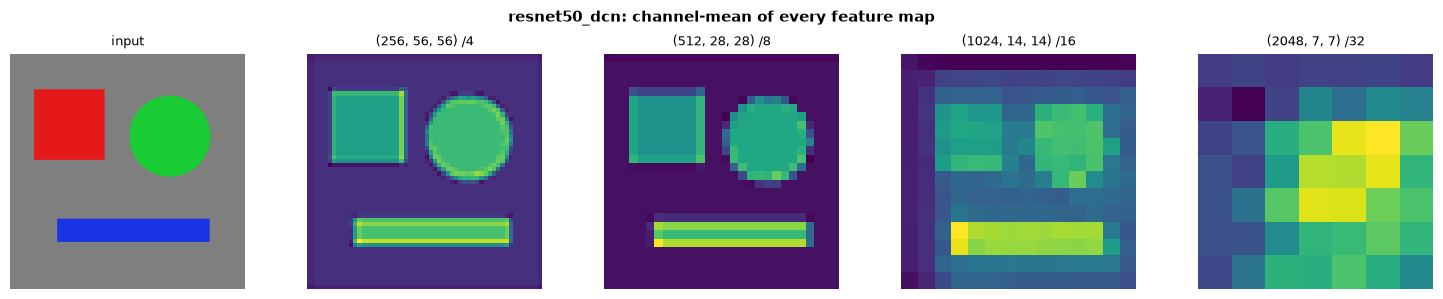

In [15]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [16]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [17]:
import sys

import torch

x = torch.randn(1, 3, 224, 224)

for name in ['resnet50', 'resnet50_dcn', 'resnet101_dcn']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    with torch.no_grad():
        out = bb(x)
    params = bb.num_parameters()
    print(f'{name:15s}  pooled={tuple(out.pooled_output.shape)}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  parameters: {params:,}  (vs resnet50: 25M — DCN adds ~2M offset/mask params)')
    print()

resnet50         pooled=(1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  parameters: 23,508,032  (vs resnet50: 25M — DCN adds ~2M offset/mask params)



resnet50_dcn     pooled=(1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  parameters: 24,254,771  (vs resnet50: 25M — DCN adds ~2M offset/mask params)



resnet101_dcn    pooled=(1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  parameters: 44,304,894  (vs resnet50: 25M — DCN adds ~2M offset/mask params)



## References

1. **[Primary DCNv2]** Zhu, X., Hu, H., Lin, S., & Dai, J. (2019). **Deformable ConvNets v2: More Deformable, Better Results**. *CVPR 2019*. https://arxiv.org/abs/1811.11168

2. **[Original DCNv1]** Dai, J., Qi, H., Xiong, Y., Li, Y., Zhang, G., Hu, H., & Wei, Y. (2017). **Deformable Convolutional Networks**. *ICCV 2017*. https://arxiv.org/abs/1703.06211

3. Wang, W., et al. (2022). **InternImage**. *CVPR 2023*. — Extends to DCNv3 (separable formulation), see `internimage.ipynb`.

4. Bertasius, G., Wang, H., & Torresani, L. (2021). **Is Space-Time Attention All You Need for Video Understanding? (TimeSformer)**. — Shows deformable attention analogues in video transformers.

5. Zhu, X., Su, W., Lu, L., Li, B., Wang, X., & Dai, J. (2021). **Deformable DETR**. *ICLR 2021*. — Applies deformable attention to transformer-based object detection, O(1) sampling per head.